In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
os.makedirs("../screenshots", exist_ok=True)

df = pd.read_csv("../Data/telco_churn_cleaned.csv")
print(df.shape)  # expect (7043, 27)

(7043, 27)


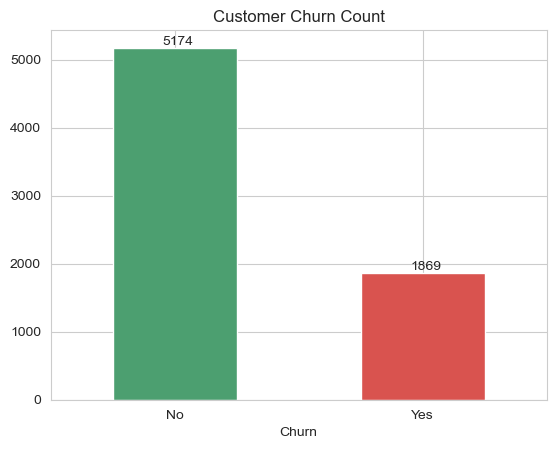

In [2]:
ax = df["Churn"].value_counts().plot(kind="bar", color=["#4C9F70", "#D9534F"])
plt.title("Customer Churn Count")
plt.xticks(rotation=0)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + 0.2, p.get_height() + 40))
plt.savefig("../screenshots/eda_01_churn_distribution.png", bbox_inches="tight")
plt.show()

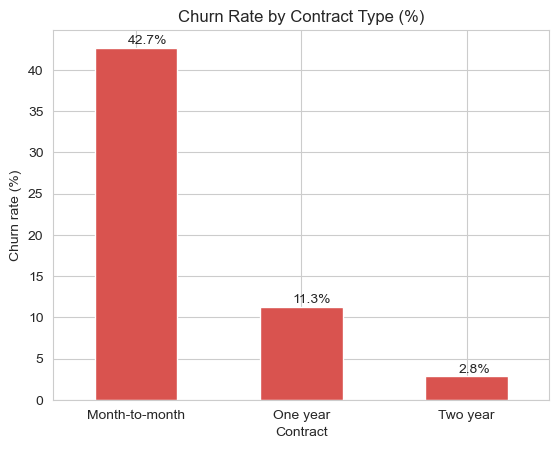

In [3]:
rate = df.groupby("Contract")["Churn_flag"].mean().mul(100).sort_values(ascending=False)
ax = rate.plot(kind="bar", color="#D9534F")
plt.title("Churn Rate by Contract Type (%)")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + 0.2, p.get_height() + 0.5))
plt.savefig("../screenshots/eda_02_churn_by_contract.png", bbox_inches="tight")
plt.show()

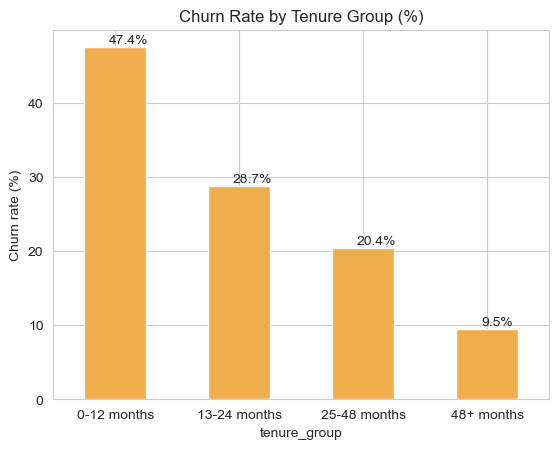

In [4]:
order = ["0-12 months", "13-24 months", "25-48 months", "48+ months"]
rate = df.groupby("tenure_group")["Churn_flag"].mean().mul(100).reindex(order)
ax = rate.plot(kind="bar", color="#F0AD4E")
plt.title("Churn Rate by Tenure Group (%)")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + 0.2, p.get_height() + 0.5))
plt.savefig("../screenshots/eda_03_churn_by_tenure.png", bbox_inches="tight")
plt.show()

C:\Users\niyam\AppData\Local\Temp\ipykernel_2052\717502545.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#4C9F70", "#D9534F"])


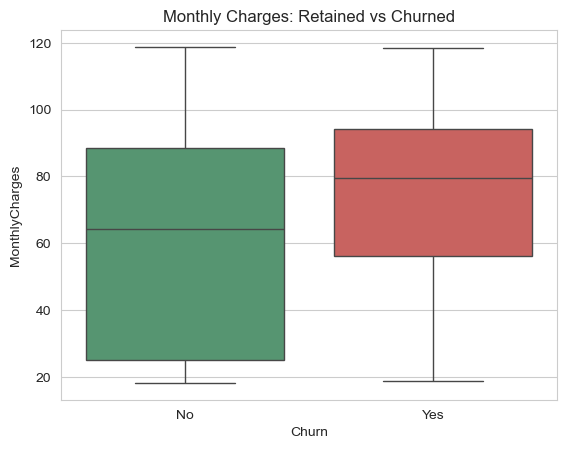

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [5]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#4C9F70", "#D9534F"])
plt.title("Monthly Charges: Retained vs Churned")
plt.savefig("../screenshots/eda_04_charges_boxplot.png", bbox_inches="tight")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

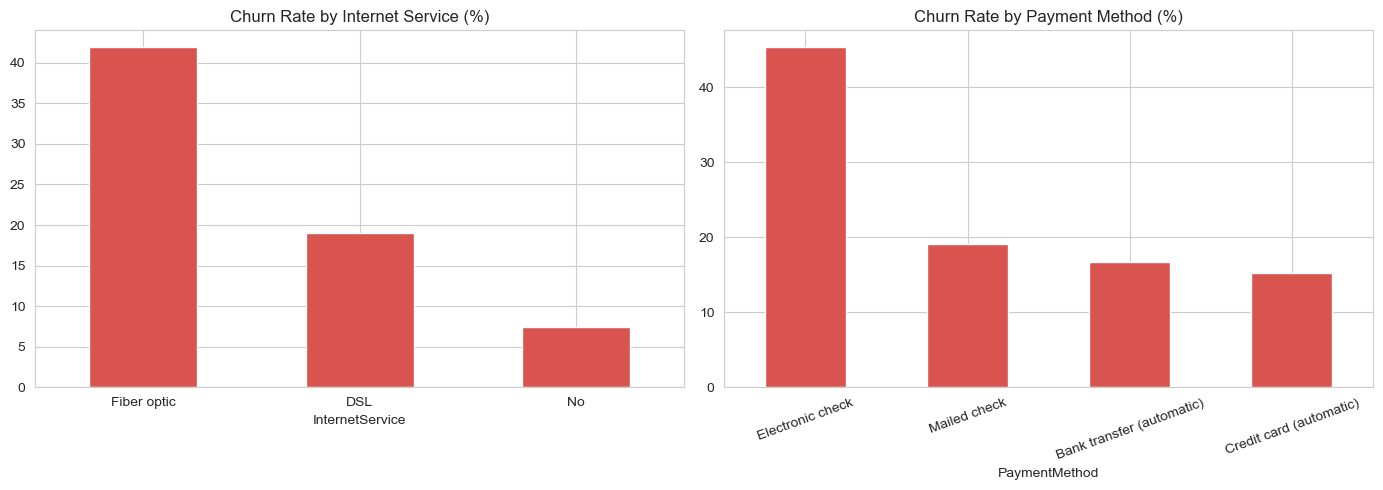

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.groupby("InternetService")["Churn_flag"].mean().mul(100).sort_values(ascending=False) \
  .plot(kind="bar", ax=axes[0], color="#D9534F")
axes[0].set_title("Churn Rate by Internet Service (%)")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("PaymentMethod")["Churn_flag"].mean().mul(100).sort_values(ascending=False) \
  .plot(kind="bar", ax=axes[1], color="#D9534F")
axes[1].set_title("Churn Rate by Payment Method (%)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("../screenshots/eda_05_internet_payment.png", bbox_inches="tight")
plt.show()

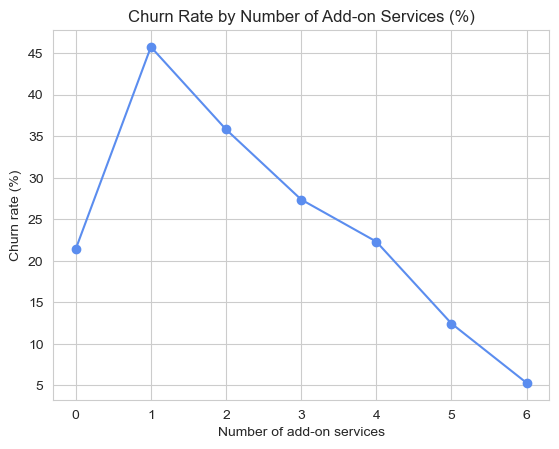

In [7]:
rate = df.groupby("num_services")["Churn_flag"].mean().mul(100)
ax = rate.plot(kind="line", marker="o", color="#5B8DEF")
plt.title("Churn Rate by Number of Add-on Services (%)")
plt.xlabel("Number of add-on services")
plt.ylabel("Churn rate (%)")
plt.savefig("../screenshots/eda_06_services.png", bbox_inches="tight")
plt.show()

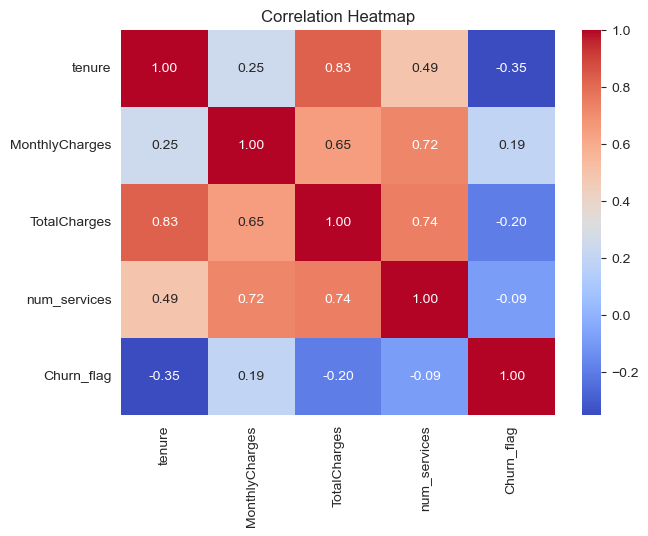

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_services", "Churn_flag"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../screenshots/eda_07_heatmap.png", bbox_inches="tight")
plt.show()

In [9]:
internet = df[df["InternetService"] != "No"]
print(internet.groupby("num_services")["Churn_flag"].mean().mul(100).round(1))

num_services
0    52.2
1    45.8
2    35.8
3    27.4
4    22.3
5    12.4
6     5.3
Name: Churn_flag, dtype: float64
